# Grammar Scoring Engine for Spoken Audio

**Goal:** predict a continuous grammar score (0-5) from a 45-60 s audio clip.

**Idea in one line:** grammar is about *what words were said*, so first turn speech into text (Whisper),
then measure how grammatical / fluent that text looks, add some audio information, and train a simple regression model.

Pipeline:
1. Load data
2. Speech -> text with Whisper
3. Build features (hand-made text features, GPT-2 perplexity, sentence embeddings, wav2vec2 audio embeddings)
4. Train simple models (Ridge, SVR) with 5-fold cross-validation and ensemble them
5. Evaluate (RMSE, Pearson), visualise, predict the test set

A full written report is at the bottom of the notebook.

## 0. Setup

In [1]:
# Run once if packages are missing (Kaggle/Colab):
# !pip install -q transformers sentence-transformers librosa scikit-learn pandas matplotlib seaborn scipy

import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import librosa, torch
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

Using device: cuda


## 1. Load the data
Change `DATA_DIR` to the folder that holds `train.csv`, `test.csv`, `sample_submission.csv` and the `.wav` files.
The code auto-detects the file-name column (first column) and the label column (last column of train.csv).

In [3]:
DATA_DIR = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
CACHE_DIR = "cache"; os.makedirs(CACHE_DIR, exist_ok=True)

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test  = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

FILE_COL, LABEL_COL = train.columns[0], train.columns[-1]
print("File column:", FILE_COL, "| Label column:", LABEL_COL)

# Map every wav file name to its full path (works whatever the sub-folder layout is)
wav_paths = {os.path.basename(p): p for p in glob.glob(f"{DATA_DIR}/**/*.wav", recursive=True)}
def get_path(name):
    name = str(name)
    return wav_paths.get(name) or wav_paths.get(name + ".wav")

train["path"] = train[FILE_COL].map(get_path)
test["path"]  = test[FILE_COL].map(get_path)
print("Train:", train.shape, "| Test:", test.shape)
print("Missing audio -> train:", train.path.isna().sum(), "test:", test.path.isna().sum())
train.head()

File column: filename | Label column: label
Train: (769, 3) | Test: (216, 3)
Missing audio -> train: 0 test: 0


,filename,label,path
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...


### 1.1 Look at the labels

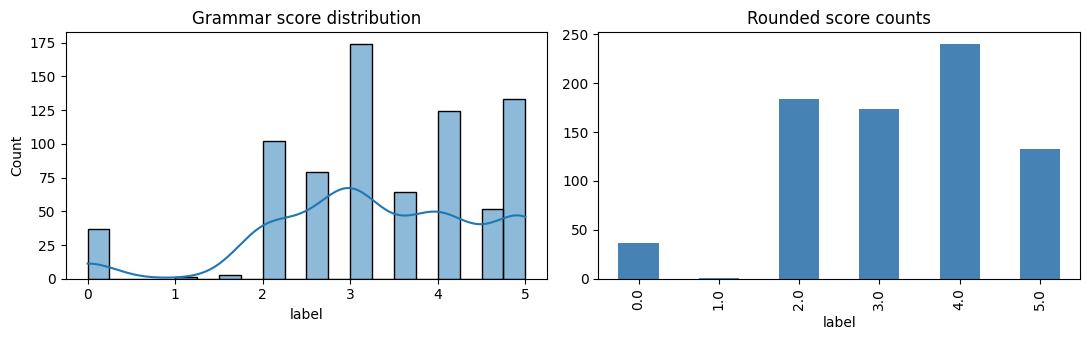

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64
Baseline (predict mean) RMSE: 1.2382


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train[LABEL_COL], bins=20, kde=True, ax=ax[0]); ax[0].set_title("Grammar score distribution")
train[LABEL_COL].round().value_counts().sort_index().plot.bar(ax=ax[1], color="steelblue")
ax[1].set_title("Rounded score counts"); plt.tight_layout(); plt.show()
print(train[LABEL_COL].describe())

# Baseline: always predict the mean. Any real model must beat this RMSE.
baseline_rmse = np.sqrt(mean_squared_error(train[LABEL_COL], np.full(len(train), train[LABEL_COL].mean())))
print(f"Baseline (predict mean) RMSE: {baseline_rmse:.4f}")

## 2. Audio loading and transcription (Whisper)
All audio is resampled to **16 kHz mono** (what Whisper and wav2vec2 expect).
Whisper is used because it transcribes what was actually said and keeps grammar mistakes fairly well
(it is not a strong "autocorrector").
Results are cached so you only pay the cost once.

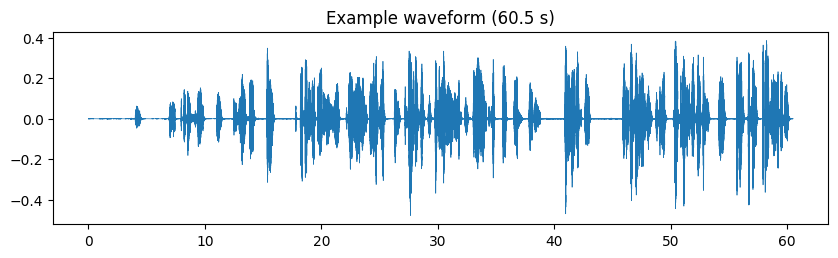

Duration min/mean/max: 20.1 / 55.8 / 61.0 s


In [5]:
SR = 16000
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y

# Quick look at one waveform
y0 = load_audio(train.path.iloc[0])
plt.figure(figsize=(10, 2.5)); plt.plot(np.arange(len(y0))/SR, y0, lw=0.5)
plt.title(f"Example waveform ({len(y0)/SR:.1f} s)"); plt.show()

durations = [librosa.get_duration(path=p) for p in train.path]
print(f"Duration min/mean/max: {min(durations):.1f} / {np.mean(durations):.1f} / {max(durations):.1f} s")

In [6]:
from transformers import pipeline

def transcribe_all(df, cache_file):
    if os.path.exists(cache_file):
        return pd.read_csv(cache_file)["text"].fillna("").tolist()
    asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
                   device=0 if DEVICE == "cuda" else -1, chunk_length_s=30, batch_size=8)
    texts = []
    for p in tqdm(df.path, desc="Transcribing"):
        out = asr({"raw": load_audio(p), "sampling_rate": SR}, generate_kwargs={"language": "en", "task": "transcribe"})
        texts.append(out["text"].strip())
    pd.DataFrame({"text": texts}).to_csv(cache_file, index=False)
    return texts

train["text"] = transcribe_all(train, f"{CACHE_DIR}/train_text.csv")
test["text"]  = transcribe_all(test,  f"{CACHE_DIR}/test_text.csv")
for i in range(3):
    print(f"[score {train[LABEL_COL].iloc[i]}] {train.text.iloc[i][:300]}\n")

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

...

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Transcribing:   0%|          | 0/216 [00:00<?, ?it/s]

[score 3.0] The playground is very, very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of pair, because one fits in it and the other fits in it will have to push and may go around to just find points and mos

[score 3.0] The scene of a school playground. Our playground looks like a very big playground having a more greenery trees. In which we students like to garden more trees to have fresh air and all having fresh oxygen. These in the playground these trees gives a very greenery view which will very pleasant to our

[score 3.5] My favorite place to visit is the beach. I love the sound of the waves crashing against the shore. The feeling of the sand between my toys and the small smell of the salt water. I love the fact that there is always something to do at the beach. I can swim, sun bath, build sandcastle or just relax an



## 3. Feature engineering
Four groups of features, each easy to explain:

| Group | What it captures |
|---|---|
| **Hand-made text features** | length, vocabulary variety, sentence length, filler words, repeated words, speech rate, pauses |
| **GPT-2 perplexity** | how "natural/grammatical" the transcript is for a language model (lower = more fluent) |
| **Sentence embedding** (MiniLM) | general meaning/style of the text |
| **wav2vec2 embedding** | pronunciation / fluency information straight from the audio |

### 3.1 Hand-made features + pauses

In [7]:
FILLERS = {"um", "uh", "umm", "uhh", "er", "erm", "hmm", "ah", "like"}

def handcrafted(text, path):
    words = re.findall(r"[a-zA-Z']+", text.lower())
    sents = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    n = max(len(words), 1)
    bigrams = list(zip(words, words[1:]))
    y = load_audio(path); dur = len(y) / SR
    voiced = librosa.effects.split(y, top_db=30)                    # non-silent segments
    voiced_time = sum(e - s for s, e in voiced) / SR
    gaps = [(voiced[i+1][0] - voiced[i][1]) / SR for i in range(len(voiced)-1)]
    return {
        "n_words": len(words),
        "words_per_sec": len(words) / dur,
        "unique_ratio": len(set(words)) / n,
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "n_sentences": len(sents),
        "avg_sent_len": len(words) / max(len(sents), 1),
        "filler_ratio": sum(w in FILLERS for w in words) / n,
        "repeat_word_ratio": sum(a == b for a, b in bigrams) / max(len(bigrams), 1),
        "repeat_bigram_ratio": 1 - len(set(bigrams)) / max(len(bigrams), 1),
        "comma_ratio": text.count(",") / n,
        "speech_ratio": voiced_time / dur,
        "n_long_pauses": sum(g > 0.5 for g in gaps),
        "mean_pause": np.mean(gaps) if gaps else 0,
    }

def build_hand(df, name):
    f = f"{CACHE_DIR}/{name}_hand.csv"
    if os.path.exists(f): return pd.read_csv(f)
    out = pd.DataFrame([handcrafted(t, p) for t, p in tqdm(zip(df.text, df.path), total=len(df), desc=name)])
    out.to_csv(f, index=False); return out

Xh_train, Xh_test = build_hand(train, "train"), build_hand(test, "test")
Xh_train.describe().T[["mean", "std", "min", "max"]]

train:   0%|          | 0/769 [00:00<?, ?it/s]

test:   0%|          | 0/216 [00:00<?, ?it/s]

,mean,std,min,max
n_words,107.228869,71.289698,26.000000,1108.000000
words_per_sec,1.928366,1.195808,0.432795,18.443708
unique_ratio,0.598582,0.121661,0.028881,0.964286
avg_word_len,4.219926,0.416380,2.916803,5.875000
n_sentences,6.336801,13.623173,1.000000,225.000000
avg_sent_len,30.961672,32.070374,1.093333,485.000000
filler_ratio,0.008557,0.015233,0.000000,0.182708
repeat_word_ratio,0.006307,0.048163,0.000000,0.902041
repeat_bigram_ratio,0.114016,0.135263,0.000000,0.963866
comma_ratio,0.033576,0.037488,0.000000,0.358891


### 3.2 GPT-2 perplexity (grammaticality proxy)

In [8]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

def perplexity_feats(texts, name):
    f = f"{CACHE_DIR}/{name}_ppl.csv"
    if os.path.exists(f): return pd.read_csv(f)
    tok = GPT2TokenizerFast.from_pretrained("gpt2")
    lm = GPT2LMHeadModel.from_pretrained("gpt2").to(DEVICE).eval()
    rows = []
    for t in tqdm(texts, desc=name):
        ids = tok(t if t.strip() else ".", return_tensors="pt", truncation=True, max_length=1024).input_ids.to(DEVICE)
        with torch.no_grad():
            logits = lm(ids).logits[0, :-1]
        # per-token negative log-likelihood
        nll = torch.nn.functional.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
        rows.append({"gpt2_mean_nll": nll.mean(), "gpt2_median_nll": np.median(nll),
                     "gpt2_p90_nll": np.percentile(nll, 90), "gpt2_frac_high_nll": (nll > 6).mean()})
    out = pd.DataFrame(rows); out.to_csv(f, index=False); return out

Xp_train, Xp_test = perplexity_feats(train.text, "train"), perplexity_feats(test.text, "test")
print(pd.concat([Xp_train, train[LABEL_COL]], axis=1).corr()[LABEL_COL].round(3))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

train:   0%|          | 0/769 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

test:   0%|          | 0/216 [00:00<?, ?it/s]

gpt2_mean_nll        -0.014
gpt2_median_nll      -0.007
gpt2_p90_nll          0.046
gpt2_frac_high_nll   -0.110
label                 1.000
Name: label, dtype: float64


### 3.3 Text embeddings (sentence-transformers)

In [9]:
from sentence_transformers import SentenceTransformer
st = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
Xt_train = st.encode(train.text.tolist(), batch_size=32, show_progress_bar=True)
Xt_test  = st.encode(test.text.tolist(),  batch_size=32, show_progress_bar=True)
print(Xt_train.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

(769, 384)


### 3.4 Audio embeddings (wav2vec2, mean-pooled)

In [10]:
from transformers import Wav2Vec2Processor, Wav2Vec2Model

def audio_embeddings(df, name):
    f = f"{CACHE_DIR}/{name}_w2v.npy"
    if os.path.exists(f): return np.load(f)
    proc = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
    m = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h").to(DEVICE).eval()
    embs = []
    for p in tqdm(df.path, desc=name):
        inp = proc(load_audio(p), sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        with torch.no_grad():
            h = m(inp).last_hidden_state[0]                 # (time, 768)
        embs.append(h.mean(0).cpu().numpy())                # average over time -> 768 numbers
    embs = np.vstack(embs); np.save(f, embs); return embs

Xa_train, Xa_test = audio_embeddings(train, "train"), audio_embeddings(test, "test")
print(Xa_train.shape)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

...

train:   0%|          | 0/769 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.weight    | UNEXPECTED | 
lm_head.bias      | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


test:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 768)


### 3.5 Combine features
The two embedding blocks are large (384 and 768 columns) compared to only 769 training samples,
so each is reduced with **PCA** (fit inside cross-validation to avoid leakage) before being joined to the small, informative feature table.

In [13]:
y = train[LABEL_COL].values.astype(float)

small_train = pd.concat([Xh_train, Xp_train], axis=1).values
small_test  = pd.concat([Xh_test,  Xp_test],  axis=1).values
small_names = list(Xh_train.columns) + list(Xp_train.columns)

def make_features(idx_fit, idx_apply, small, text_emb, audio_emb, small_other=None, text_other=None, audio_other=None, n_pca=20):
    # Fit scalers / PCA ONLY on the fitting rows, then transform the rest.
    sc = StandardScaler().fit(small[idx_fit])
    pt = make_pipeline(StandardScaler(), PCA(n_pca, random_state=SEED)).fit(text_emb[idx_fit])
    pa = make_pipeline(StandardScaler(), PCA(n_pca, random_state=SEED)).fit(audio_emb[idx_fit])
    build = lambda s, t, a: np.hstack([sc.transform(s), pt.transform(t), pa.transform(a)])
    return build(small[idx_fit], text_emb[idx_fit], audio_emb[idx_fit]), \
           build(small[idx_apply], text_emb[idx_apply], audio_emb[idx_apply]) if small_other is None else \
           build(small_other, text_other, audio_other)

## 4. Models and 5-fold cross-validation
Two simple models:
* **Ridge regression** - linear, with regularisation so it does not overfit.
* **SVR (RBF)** - can learn mild non-linear patterns.

Final prediction = **average of the two**, clipped into [0, 5].
Out-of-fold (OOF) predictions give an honest estimate of test performance.

In [14]:
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def evaluate(name, yt, yp):
    yp = np.clip(yp, 0, 5)
    return {"model": name, "RMSE": rmse(yt, yp), "Pearson": pearsonr(yt, yp)[0]}

def get_models():
    return {"Ridge": Ridge(alpha=10.0), "SVR": SVR(C=2.0, epsilon=0.1, gamma="scale")}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {k: np.zeros(len(y)) for k in get_models()}

for fold, (tr, va) in enumerate(kf.split(small_train), 1):
    Xtr, Xva = make_features(tr, va, small_train, Xt_train, Xa_train)
    for name, model in get_models().items():
        model.fit(Xtr, y[tr]); oof[name][va] = model.predict(Xva)
    print(f"fold {fold} done")

oof["Ensemble"] = (oof["Ridge"] + oof["SVR"]) / 2
cv_results = pd.DataFrame([evaluate(k, y, v) for k, v in oof.items()])
cv_results.loc[len(cv_results)] = {"model": "Baseline (mean)", "RMSE": baseline_rmse, "Pearson": np.nan}
print("Cross-validated results (out-of-fold):"); cv_results.round(4)

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
Cross-validated results (out-of-fold):


,model,RMSE,Pearson
0,Ridge,0.6762,0.8378
1,SVR,0.7063,0.8218
2,Ensemble,0.6567,0.8487
3,Baseline (mean),1.2382,NaN


### 4.1 Ablation: which feature group helps?
A quick check that each part is actually useful (Ridge, 5-fold CV).

In [15]:
def quick_cv(get_X):
    pred = np.zeros(len(y))
    for tr, va in kf.split(y):
        Xtr, Xva = get_X(tr, va)
        pred[va] = Ridge(alpha=10.0).fit(Xtr, y[tr]).predict(Xva)
    return rmse(y, np.clip(pred, 0, 5)), pearsonr(y, np.clip(pred, 0, 5))[0]

def only(block):
    def f(tr, va):
        if block == "text feats":
            sc = StandardScaler().fit(small_train[tr]); return sc.transform(small_train[tr]), sc.transform(small_train[va])
        emb = Xt_train if block == "text emb" else Xa_train
        p = make_pipeline(StandardScaler(), PCA(20, random_state=SEED)).fit(emb[tr]); return p.transform(emb[tr]), p.transform(emb[va])
    return f

abl = {b: quick_cv(only(b)) for b in ["text feats", "text emb", "audio emb"]}
abl["all combined"] = quick_cv(lambda tr, va: make_features(tr, va, small_train, Xt_train, Xa_train))
abl_df = pd.DataFrame(abl, index=["RMSE", "Pearson"]).T.round(4); abl_df

,RMSE,Pearson
text feats,0.9951,0.5957
text emb,1.0870,0.4791
audio emb,0.7853,0.7733
all combined,0.6762,0.8378


## 5. Evaluation and visualisation

In [16]:
# --- Training RMSE (REQUIRED): fit on ALL training data, then score the same training data ---
all_idx = np.arange(len(y))
Xfull, _ = make_features(all_idx, all_idx, small_train, Xt_train, Xa_train)
final_models = {n: m.fit(Xfull, y) for n, m in get_models().items()}
train_pred = np.clip(np.mean([m.predict(Xfull) for m in final_models.values()], axis=0), 0, 5)

TRAIN_RMSE = rmse(y, train_pred)
CV_RMSE = rmse(y, np.clip(oof["Ensemble"], 0, 5))
print(f"TRAINING RMSE : {TRAIN_RMSE:.4f}   (model scored on data it was trained on - optimistic)")
print(f"CV RMSE       : {CV_RMSE:.4f}   (out-of-fold - realistic estimate for test)")
print(f"CV Pearson    : {pearsonr(y, np.clip(oof['Ensemble'], 0, 5))[0]:.4f}")
print(f"Baseline RMSE : {baseline_rmse:.4f}")

TRAINING RMSE : 0.4667   (model scored on data it was trained on - optimistic)
CV RMSE       : 0.6567   (out-of-fold - realistic estimate for test)
CV Pearson    : 0.8487
Baseline RMSE : 1.2382


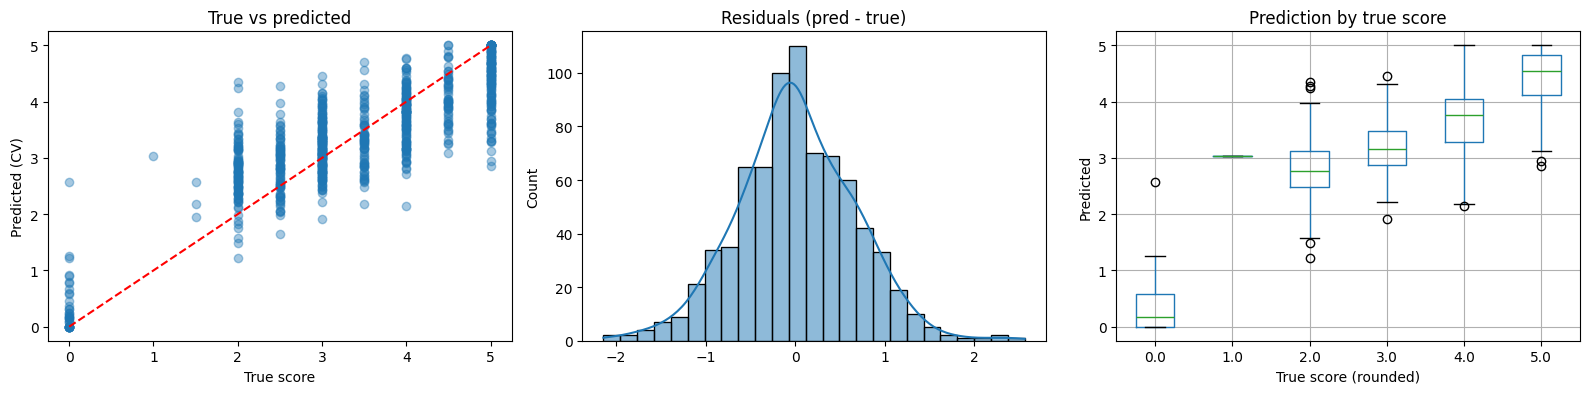

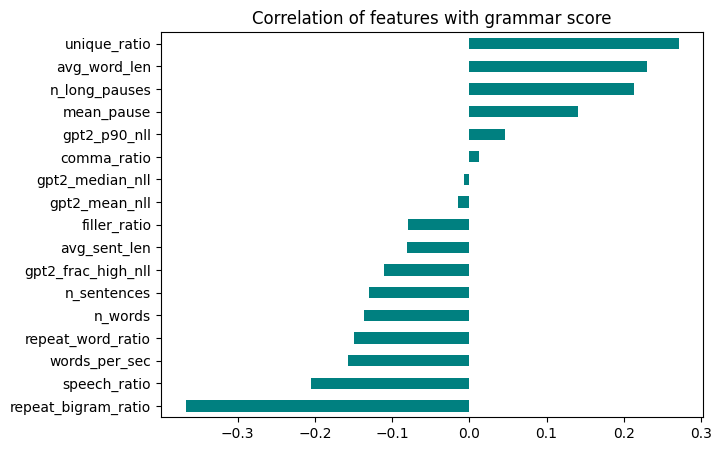

In [17]:
pred_cv = np.clip(oof["Ensemble"], 0, 5)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].scatter(y, pred_cv, alpha=0.4); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set(xlabel="True score", ylabel="Predicted (CV)", title="True vs predicted")

sns.histplot(pred_cv - y, bins=25, kde=True, ax=ax[1]); ax[1].set_title("Residuals (pred - true)")

pd.DataFrame({"true": y.round(), "pred": pred_cv}).boxplot(column="pred", by="true", ax=ax[2])
ax[2].set(title="Prediction by true score", xlabel="True score (rounded)", ylabel="Predicted"); plt.suptitle("")
plt.tight_layout(); plt.show()

# Which hand-made features correlate most with the score?
corr = pd.concat([pd.DataFrame(small_train, columns=small_names), pd.Series(y, name="score")], axis=1).corr()["score"].drop("score")
corr.sort_values().plot.barh(figsize=(7, 5), color="teal"); plt.title("Correlation of features with grammar score"); plt.show()

## 6. Predict the test set and create the submission

In [20]:
print(sample_sub.shape, test.shape)
print(sample_sub.columns.tolist(), test.columns.tolist())

s_names = set(sample_sub[sample_sub.columns[0]].astype(str))
t_names = set(test[FILE_COL].astype(str))
print("In test but not in sample:", len(t_names - s_names))
print("In sample but not in test:", len(s_names - t_names))

(204, 2) (216, 4)
['filename', 'label'] ['filename', 'label', 'path', 'text']
In test but not in sample: 191
In sample but not in test: 179


In [21]:
_, Xtest_final = make_features(all_idx, None, small_train, Xt_train, Xa_train,
                               small_other=small_test, text_other=Xt_test, audio_other=Xa_test)
test_pred = np.clip(np.mean([m.predict(Xtest_final) for m in final_models.values()], axis=0), 0, 5)

id_col, label_col = sample_sub.columns[0], sample_sub.columns[-1]
submission = pd.DataFrame({id_col: test[FILE_COL].values, label_col: test_pred})

# Keep the file-name format identical to the sample (e.g. with or without ".wav")
if str(sample_sub[id_col].iloc[0]).endswith(".wav") and not str(submission[id_col].iloc[0]).endswith(".wav"):
    submission[id_col] = submission[id_col].astype(str) + ".wav"

submission.to_csv("submission.csv", index=False)
print(submission.shape)
submission.head()

(216, 2)


,filename,label
0,audio_128.wav,3.055695
1,audio_156.wav,3.386689
2,audio_19.wav,3.871161
3,audio_108.wav,2.714080
4,audio_206.wav,4.625000


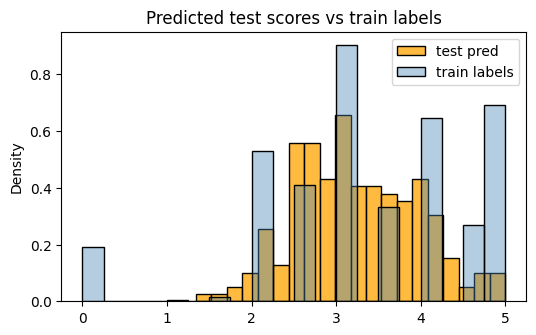

In [22]:
plt.figure(figsize=(6, 3.5))
sns.histplot(test_pred, bins=20, color="orange", label="test pred", stat="density")
sns.histplot(y, bins=20, color="steelblue", alpha=0.4, label="train labels", stat="density")
plt.legend(); plt.title("Predicted test scores vs train labels"); plt.show()

## 7. Report

### Problem
Predict a grammar score from 0 to 5 for 45-60 s spoken clips. Metrics: RMSE (lower is better) and Pearson correlation (higher is better).

### Approach
Grammar is a property of the words and sentence structure, so the problem is split in two:
1. **Speech -> text** with OpenAI **Whisper-small**.
2. **Text (+ audio) -> score** with classic regression on engineered features.

I chose this over fine-tuning a large end-to-end audio model because only 769 clips are available. Large models overfit that little data, and a pipeline of pretrained parts plus a simple regressor is easy to explain.

### Preprocessing
* Audio resampled to 16 kHz mono.
* Transcripts cached to disk.
* Features standardised, embeddings reduced with PCA (20 components each); scalers and PCA are **fit only on training folds** to avoid data leakage.
* Predictions clipped to [0, 5].

### Features
1. **Hand-made**: word count, speech rate, vocabulary variety, sentence length, fillers, repetitions, pause statistics.
2. **GPT-2 perplexity** stats: ungrammatical or broken sentences get higher per-token loss.
3. **MiniLM sentence embedding** of the transcript.
4. **wav2vec2 embedding** of the audio (mean over time).

### Model
Ridge regression + RBF-SVR, averaged (ensemble). Chosen because they are stable on small data and easy to explain.

### Evaluation
* **Training RMSE**, 5-fold **CV RMSE**, CV Pearson and a mean-prediction baseline are printed in section 5 (the training RMSE is also stored in `TRAIN_RMSE`).
* The CV numbers are the honest estimate; training RMSE is lower because the model has seen those samples.
* Plots: label distribution, true vs predicted, residuals, per-score boxplot, feature correlations, ablation table.

### Limitations and next steps
* Whisper can partially "fix" grammar mistakes and may mis-hear accented speech, which weakens the signal.
* Labels are subjective Likert ratings, so some noise is unavoidable.
* Ideas: add a grammar checker (e.g. LanguageTool) error count, use Whisper-medium, fine-tune a small text model (DeBERTa) on transcripts, or try LightGBM/CatBoost on the feature table.